In [1]:
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.manifold import TSNE
from sklearn.cluster import AgglomerativeClustering
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
dtm = pd.read_csv("tfidf_scores.csv", index_col = 0)

In [3]:
print("Number of dimensions per text:", len(dtm.columns))

Number of dimensions per text: 16026


In [4]:
sims = cosine_similarity(dtm)
sims = pd.DataFrame(sims, columns = dtm.index, index = dtm.index)
sims.iloc[:5, :5]

basename,ra_10924_2016,ra_10923_2016,ra_10925_2017,ra_10926_2017,ra_10927_2017
basename,,,,,
ra_10924_2016,1.000000,0.123936,0.130228,0.159211,0.130562
ra_10923_2016,0.123936,1.000000,0.058489,0.112565,0.078620
ra_10925_2017,0.130228,0.058489,1.000000,0.541950,0.063779
ra_10926_2017,0.159211,0.112565,0.541950,1.000000,0.112313
ra_10927_2017,0.130562,0.078620,0.063779,0.112313,1.000000


In [5]:
reducer = TSNE(
    n_components = 2,
    learning_rate = 'auto',
    init = 'random',
    angle = 0.35,
    random_state = 357,
    n_jobs = -1
)
reduced = reducer.fit_transform(sims)
vis = pd.DataFrame({'x': reduced[:,0], 'y': reduced[:,1], 'label': sims.index})

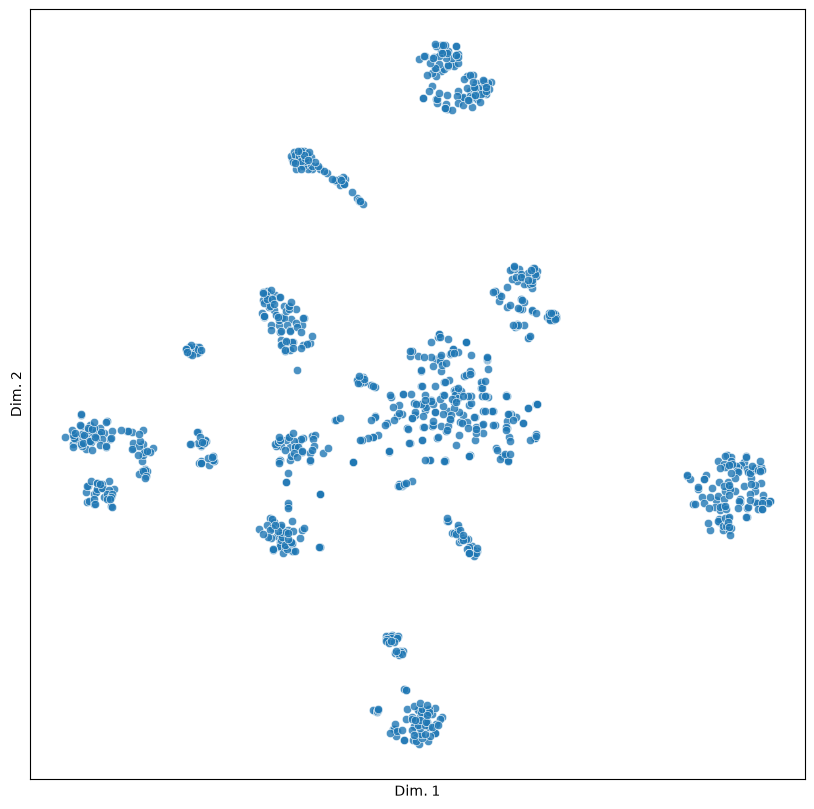

In [6]:
def sim_plot(data, hue = None, labels = None, n_colors = 3, palette = 'deep'):
    """Create a scatterplot and optionally color/label its points."""
    fig, ax = plt.subplots(figsize = (10, 10))
    pal = sns.color_palette(palette, n_colors = n_colors) if hue else None
    g = sns.scatterplot(
        x = 'x', y = 'y', hue = hue, palette = pal, alpha = 0.8,
        data = data, ax = ax
    )
    g.set(xticks = [], yticks = [], xlabel = 'Dim. 1', ylabel = 'Dim. 2')

    if labels:
        to_label = data[data['label'].isin(labels)]
        to_label[['x', 'y', 'label']].apply(lambda x: g.text(*x), axis = 1)

    plt.show()

sim_plot(vis)

In [7]:
k = 10
agg = AgglomerativeClustering(n_clusters = k)
agg.fit(sims)

AgglomerativeClustering(n_clusters=10)

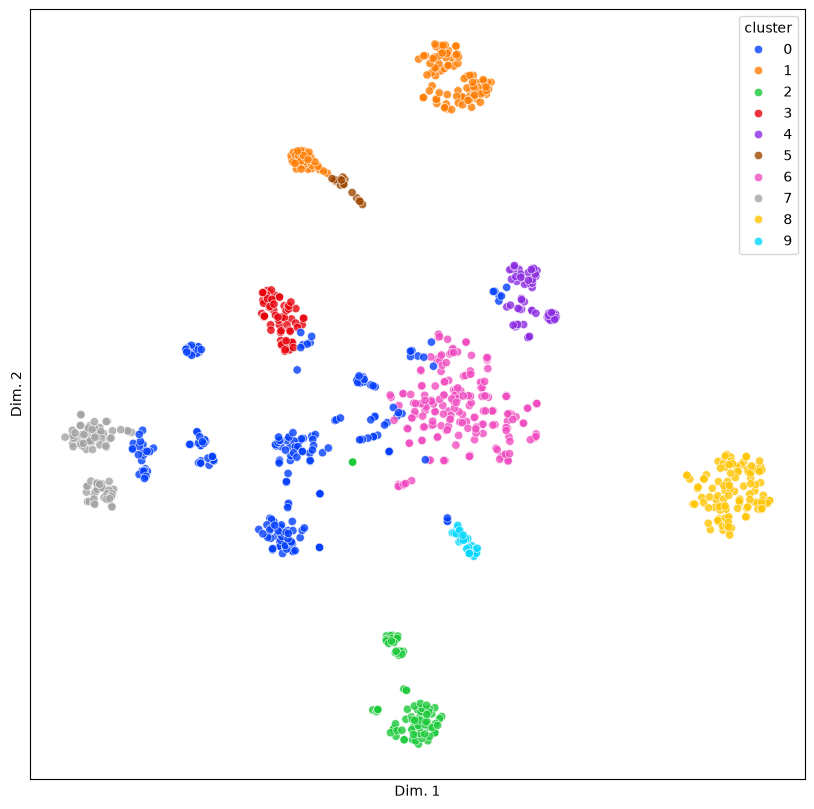

In [8]:
vis.loc[:, 'cluster'] = agg.labels_
sim_plot(vis, hue = 'cluster', n_colors=k, palette='bright') 

In [9]:
n_sample = 5
for group in vis.groupby('cluster'):
    cluster, subset = group
    print(f"Cluster: {cluster}\n----------")
    samp = subset.sample(n_sample)
    for label in samp['label']:
        print(label)
    print("\n")

Cluster: 0
----------
ra_11050_2018
ra_11424_2019
ra_11663_2022
ra_11652_2022
ra_11048_2018


Cluster: 1
----------
ra_11004_2018
ra_11542_2021
ra_11482_2020
ra_11422_2019
ra_11834_2022


Cluster: 2
----------
ra_11427_2019
ra_11804_2022
ra_11066_2018
ra_11432_2019
ra_11748_2022


Cluster: 3
----------
ra_10966_2017
ra_11216_2019
ra_11135_2018
ra_11145_2018
ra_11144_2018


Cluster: 4
----------
ra_11751_2022
ra_11186_2019
ra_11006_2018
ra_11348_2019
ra_11282_2019


Cluster: 5
----------
ra_11842_2022
ra_11357_2019
ra_11420_2019
ra_11682_2022
ra_11505_2020


Cluster: 6
----------
ra_11571_2021
ra_11650_2022
ra_11467_2020
ra_11232_2019
ra_11313_2019


Cluster: 7
----------
ra_11023_2018
ra_11070_2018
ra_11622_2021
ra_10978_2018
ra_10979_2018


Cluster: 8
----------
ra_11472_2020
ra_11880_2022
ra_11870_2022
ra_11891_2022
ra_11390_2019


Cluster: 9
----------
ra_11811_2022
ra_10940_2017
ra_11912_2022
ra_11776_2022
ra_10943_2017


